# Chapter 4 · Static replication and the Kolmogorov equations: interactive demos

Companion to Chapter 4 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/04-static-replication.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider, Checkbox, Dropdown

from mfe230d import bs
from mfe230d.replication import (bs_market, discounted_expectation, fd_grid, forward_solve, backward_solve,
                                 grid_payoff, grid_price, grid_replication, power_call, power_params,
                                 skew_local_vol)
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
TC = bs.TEST_CASE          # S = K = 100, T = 1, r = 1%, y = 2%, sigma = 20%
S0, T, R, Y, SIG = TC["S"], TC["T"], TC["r"], TC["y"], TC["sigma"]
use_style()

## 1. Replicating a payoff on a strike grid

A payoff is split into a continuous part $g$ (kinks and curvature) and jumps (Theorem 4.1). On a grid of strikes
with spacing $h$, the piecewise-linear interpolant of $g$ is a finite portfolio of bonds, shares and calls. If the
jumps are interpolated too, each becomes a call spread over one grid cell and the price error is of first order
in $h$, about $\frac12 J h\,G(a)$ for a jump $J$ at $a$ (equation (4.5)); holding the digitals instead
leaves an error of order $h^2$. Prices are in the test case; the exact price is computed by quadrature.

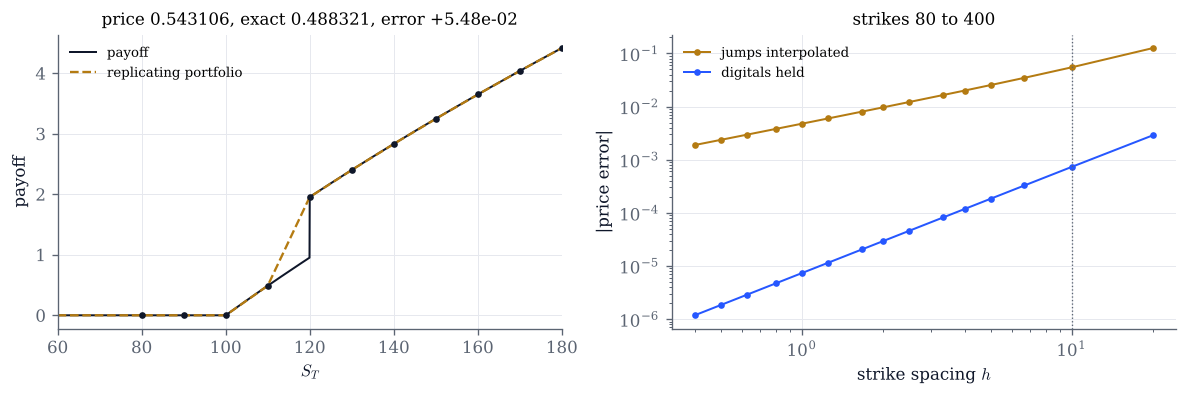

In [2]:
PAYOFFS = {
    # name: (continuous part g, list of (jump point a, jump size J), kinks for the quadrature)
    "square-root call + digital": (lambda x: np.maximum(np.sqrt(np.maximum(x, 0)) - 10.0, 0.0), [(120.0, 1.0)], [100.0]),
    "square-root call": (lambda x: np.maximum(np.sqrt(np.maximum(x, 0)) - 10.0, 0.0), [], [100.0]),
    "call spread 95/125 + digital at 110": (lambda x: np.clip(np.asarray(x, float) - 95.0, 0.0, 30.0), [(110.0, 5.0)], [95.0, 125.0]),
}
MARKET = bs_market(S0, T, R, Y, SIG)

def payoff(name, x):
    g, jumps, _ = PAYOFFS[name]
    x = np.asarray(x, dtype=float)
    return g(x) + sum(J * (x >= a) for a, J in jumps)

def exact_price(name):
    g, jumps, kinks = PAYOFFS[name]
    return (discounted_expectation(lambda s: float(g(s)), S0, T, R, Y, SIG, breaks=kinks)
            + sum(J * float(MARKET["digital"](a)) for a, J in jumps))

def strip_error(name, h, k_lo, k_hi, hold_digitals):
    g, jumps, _ = PAYOFFS[name]
    k = k_lo + h * np.arange(int(np.floor((k_hi - k_lo) / h)) + 1)
    if hold_digitals:
        rep = grid_replication(g(k), k)
        price = grid_price(rep, MARKET) + sum(J * float(MARKET["digital"](a)) for a, J in jumps)
        pay = lambda x: grid_payoff(rep, x) + sum(J * (np.asarray(x) >= a) for a, J in jumps)
    else:
        rep = grid_replication(payoff(name, k), k)
        price = grid_price(rep, MARKET)
        pay = lambda x: grid_payoff(rep, x)
    return price, pay, k

def replication_demo(name="square-root call + digital", h=10.0, k_hi=400.0, hold_digitals=False):
    k_lo = 80.0
    exact = exact_price(name)
    price, pay, k = strip_error(name, h, k_lo, k_hi, hold_digitals)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    x = np.linspace(60, 180, 2401)
    ax.plot(x, payoff(name, x), color=INK, lw=1.2, label="payoff")
    ax.plot(x, pay(x), color=GOLD, lw=1.4, ls="--", label="replicating portfolio")
    ax.plot(k[k <= 180], payoff(name, k[k <= 180]), "o", color=INK, ms=3)
    ax.set(xlabel="$S_T$", ylabel="payoff", xlim=(60, 180),
           title=f"price {price:.6f}, exact {exact:.6f}, error {price - exact:+.2e}")
    ax.legend(fontsize=8)
    hs = 20.0 / np.array([1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 25, 32, 40, 50])   # grids through 100 and 120
    for hold, color, lab in ((False, GOLD, "jumps interpolated"), (True, COBALT, "digitals held")):
        err = [abs(strip_error(name, hh, k_lo, k_hi, hold)[0] - exact) for hh in hs]
        ax2.loglog(hs, np.maximum(err, 1e-16), "o-", color=color, ms=3, lw=1.2, label=lab)
    ax2.axvline(h, color=GREY, lw=0.8, ls=":")
    ax2.set(xlabel="strike spacing $h$", ylabel="|price error|", title=f"strikes {k_lo:.0f} to {k_hi:.0f}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

replication_demo()

In [3]:
# Explore: coarse grids, a grid that stops too early (k_hi), and what holding the digitals buys.
interact(replication_demo,
         name=Dropdown(options=list(PAYOFFS), value="square-root call + digital", description="payoff"),
         h=FloatLogSlider(value=10.0, base=10, min=-0.6, max=1.3, step=0.05, continuous_update=False, description="h"),
         k_hi=FloatSlider(value=400.0, min=130.0, max=500.0, step=10.0, continuous_update=False, description="top strike"),
         hold_digitals=Checkbox(value=False, description="hold digitals"));

## 2. Power payoffs and the pre-wash

In the standard model $S^p$ is again a geometric Brownian motion, with volatility $|p|\sigma$ and yield
$y_p=r-p(r-y)-\frac12p(p-1)\sigma^2$ (Proposition 4.4). So $(S_T^p-K)^+$ is a Black–Scholes call on $S^p$ with those
inputs. Below, the pre-wash prices across strikes against a Monte Carlo estimate from exact draws of $S_T$
(our implementation, `default_rng` with the seed shown), with $95\%$ confidence bars.

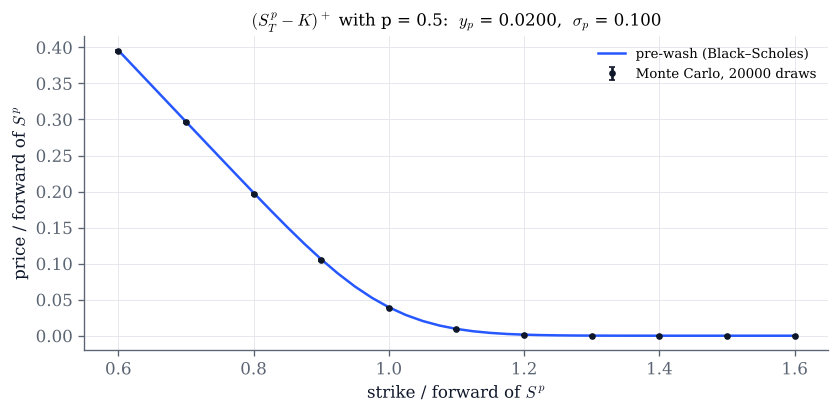

In [4]:
def power_demo(p=0.5, sigma=0.2, n=20_000, seed=1):
    rng = np.random.default_rng(seed)
    ST = S0 * np.exp((R - Y - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * rng.standard_normal(n))
    yp, sp = power_params(p, R, Y, sigma)
    fwd = S0**p * np.exp((R - yp) * T)
    Ks = fwd * np.linspace(0.6, 1.6, 41)
    Km = fwd * np.linspace(0.6, 1.6, 11)
    pay = np.exp(-R * T) * np.maximum(ST[:, None] ** p - Km, 0.0)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.plot(Ks / fwd, power_call(S0, Ks, T, R, Y, sigma, p) / fwd, color=COBALT, lw=1.5, label="pre-wash (Black–Scholes)")
    ax.errorbar(Km / fwd, pay.mean(0) / fwd, yerr=1.96 * pay.std(0, ddof=1) / np.sqrt(n) / fwd, fmt="o",
                color=INK, ms=3, capsize=2, label=f"Monte Carlo, {n} draws")
    ax.set(xlabel="strike / forward of $S^p$", ylabel="price / forward of $S^p$",
           title=f"$(S_T^p-K)^+$ with p = {p:g}:  $y_p$ = {yp:.4f},  $\\sigma_p$ = {sp:.3f}")
    ax.legend(fontsize=8)
    plt.show()

power_demo()

In [5]:
# Explore: negative p turns the call on S^p into a put-like payoff on S; p = 1 is the plain call.
interact(power_demo,
         p=FloatSlider(value=0.5, min=-2.0, max=2.0, step=0.1, continuous_update=False, description="p"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.01, continuous_update=False, description="σ"),
         n=IntSlider(value=20_000, min=2_000, max=200_000, step=2_000, continuous_update=False, description="draws"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. Euler's identity and "gamma is the density"

When the call price is homogeneous of degree one in $(S,K)$, Proposition 4.7 gives $S\partial_SC+K\partial_KC=C$ and
$(S/K)^2\partial_{SS}C=\partial_{KK}C=e^{-rT}q(K)$. Below, in the local-volatility model
$\sigma(S)=\sigma_0-\text{skew}\cdot\tanh(\log(S/100)/0.5)$, three forward solves of the Kolmogorov equation (from the spot
and its two grid neighbours) give the prices of all strikes for three spots, hence both sides of each identity.
With skew $=0$ the volatility is constant and both identities hold; with a skew, neither does
(Remark 4.8).

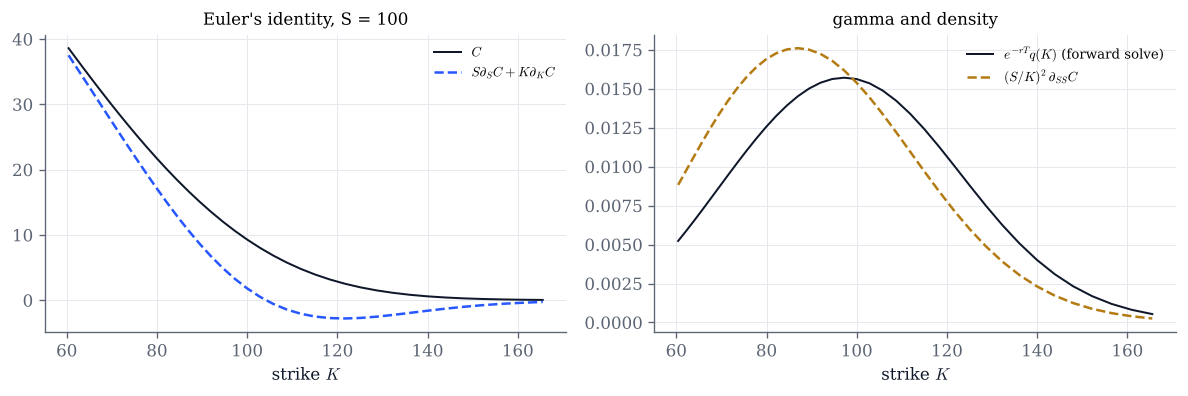

In [6]:
def euler_demo(skew=0.10, sigma0=0.25, n_t=200):
    sig = lambda s: skew_local_vol(s, sigma0=sigma0, skew=skew)
    b = lambda t, z: R - Y - 0.5 * sig(np.exp(z)) ** 2
    a = lambda t, z: sig(np.exp(z))
    x = fd_grid(np.log(S0), 8 * (sigma0 + skew), 801)
    h, i0 = x[1] - x[0], 400
    xi = np.exp(x)
    ks = 400 + np.arange(-72, 73, 4)                          # strikes on grid nodes, log-moneyness within ±0.5
    K = xi[ks]
    C = {}
    for j in (-1, 0, 1):
        G = forward_solve(x, i0 + j, T, b, a, R, n_t=n_t)
        C[j] = np.array([h * np.sum(G * np.maximum(xi - k, 0.0)) for k in K])
        if j == 0:
            G0 = G
    dCx, d2Cx = (C[1] - C[-1]) / (2 * h), (C[1] - 2 * C[0] + C[-1]) / h**2
    dS, gamma = dCx / S0, (d2Cx - dCx) / S0**2
    digital = np.array([h * (np.sum(G0[k + 1:]) + 0.5 * G0[k]) for k in ks])
    density = G0[ks] / K                                      # discounted density of S_T at K
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(K, C[0], color=INK, lw=1.2, label="$C$")
    ax.plot(K, S0 * dS - K * digital, color=COBALT, lw=1.5, ls="--", label="$S\\partial_SC+K\\partial_KC$")
    ax.set(xlabel="strike $K$", title="Euler's identity, S = 100")
    ax.legend(fontsize=8)
    ax2.plot(K, density, color=INK, lw=1.2, label="$e^{-rT}q(K)$ (forward solve)")
    ax2.plot(K, (S0 / K) ** 2 * gamma, color=GOLD, lw=1.5, ls="--", label="$(S/K)^2\\,\\partial_{SS}C$")
    ax2.set(xlabel="strike $K$", title="gamma and density")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

euler_demo()

In [7]:
# Explore: move the skew to zero and back; the gap is the price of the level-dependence of the volatility.
interact(euler_demo,
         skew=FloatSlider(value=0.10, min=0.0, max=0.15, step=0.01, continuous_update=False, description="skew"),
         sigma0=FloatSlider(value=0.25, min=0.15, max=0.40, step=0.01, continuous_update=False, description="σ0"),
         n_t=IntSlider(value=200, min=50, max=800, step=50, continuous_update=False, description="time steps"));

## 4. One forward solve, all strikes

The forward Kolmogorov equation (Theorem 4.9(iii)) propagates the density from $\delta_{x_0}$; one solve prices every
strike, and the implied volatilities show the smile that the local volatility generates. A backward solve
(Theorem 4.9(ii)) for the at-the-money call, with the transposed matrices, must give the same price up to rounding:
the difference is printed in the title.

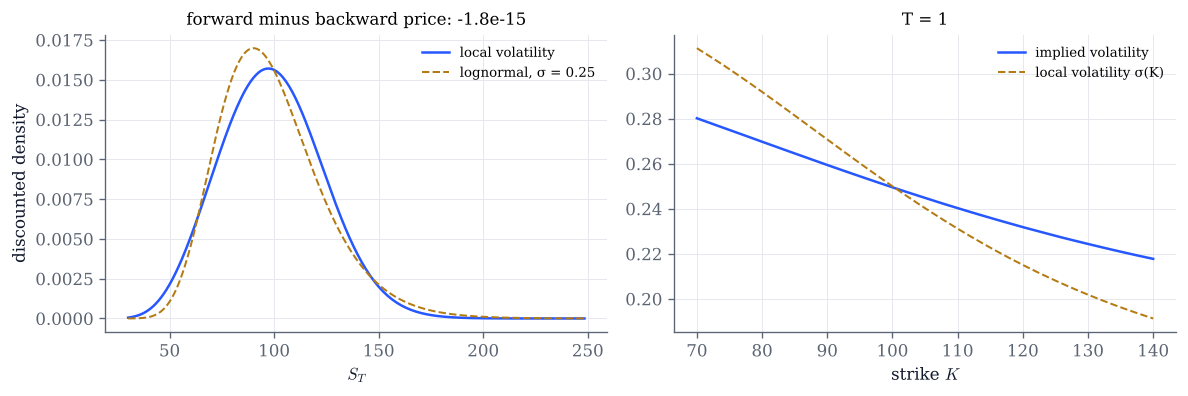

In [8]:
def kolmogorov_demo(sigma0=0.25, skew=0.10, width=0.5, T_=1.0):
    sig = lambda s: skew_local_vol(s, sigma0=sigma0, skew=skew, width=width)
    b = lambda t, z: R - Y - 0.5 * sig(np.exp(z)) ** 2
    a = lambda t, z: sig(np.exp(z))
    x = fd_grid(np.log(S0), 8 * (sigma0 + skew) * np.sqrt(max(T_, 0.25)), 801)
    h, i0 = x[1] - x[0], 400
    xi = np.exp(x)
    G = forward_solve(x, i0, T_, b, a, R, n_t=400)
    pay = np.maximum(xi - 100.0, 0.0)
    gap = h * np.sum(G * pay) - backward_solve(x, pay, T_, b, a, R, n_t=400)[i0]
    Ks = np.linspace(70, 140, 36)
    def iv_or_nan(price, k):
        try:
            return bs.implied_vol(price, S0, k, T_, R, Y)
        except ValueError:            # price below the no-arbitrage bound by discretization error
            return np.nan
    iv = [iv_or_nan(h * np.sum(G * np.maximum(xi - k, 0.0)), k) for k in Ks]
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    sel = (xi > 30) & (xi < 250)
    ax.plot(xi[sel], G[sel] / xi[sel], color=COBALT, lw=1.5, label="local volatility")
    ax.plot(xi[sel], np.exp(-R * T_) * bs.norm_pdf((np.log(xi[sel] / S0) - (R - Y - sigma0**2 / 2) * T_) / (sigma0 * np.sqrt(T_)))
            / (xi[sel] * sigma0 * np.sqrt(T_)), color=GOLD, lw=1.2, ls="--", label=f"lognormal, σ = {sigma0:.2f}")
    ax.set(xlabel="$S_T$", ylabel="discounted density", title=f"forward minus backward price: {gap:+.1e}")
    ax.legend(fontsize=8)
    ax2.plot(Ks, iv, color=COBALT, lw=1.5, label="implied volatility")
    ax2.plot(Ks, sig(Ks), color=GOLD, lw=1.2, ls="--", label="local volatility σ(K)")
    ax2.set(xlabel="strike $K$", title=f"T = {T_:g}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

kolmogorov_demo()

In [9]:
# Explore: a steeper or wider skew, and short against long maturities.
interact(kolmogorov_demo,
         sigma0=FloatSlider(value=0.25, min=0.10, max=0.40, step=0.01, continuous_update=False, description="σ0"),
         skew=FloatSlider(value=0.10, min=0.0, max=0.10, step=0.01, continuous_update=False, description="skew"),
         width=FloatSlider(value=0.5, min=0.1, max=1.5, step=0.05, continuous_update=False, description="width"),
         T_=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"));

## Things to try

- In section 1, choose the call spread and move $h$ so that the strikes $95$ and $125$ are no longer on the grid. What
  happens to the error, and why does the slope of the curve change?
- In section 1, lower the top strike to $130$. Which part of the price does the linear extrapolation get wrong?
- In section 2, find the power $p$ at which $y_p=r$. What is special about the forward of $S^p$ there?
- In section 3, at which strikes is the gap in Euler's identity largest, and how does it scale with the skew?
- In section 4, compare the slope of the implied volatility at the money with the slope of the local volatility, for
  short and long maturities.